## **Cyber-twin Smart Meter Nodes based Energy Load Forecasting using Cryptographic Federated Learning and LLM Integration**

**Federated Learning Aggregation via Summation Weight Scaling (FedAggSum_WeightScaling) based Solution**


In [ ]:
import time

start_time = time.time()

# **Libraries**

In [ ]:
!pip install keras-flops

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap # Explainable AI

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from cryptography.hazmat.primitives.ciphers import Cipher, algorithms, modes
from cryptography.hazmat.backends import default_backend
from cryptography.hazmat.primitives import hmac, hashes
import base64
from cryptography.hazmat.primitives.padding import PKCS7
from cryptography.hazmat.backends import default_backend
from io import BytesIO
import pickle

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Layer, LSTM, Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import *
from tensorflow.keras.callbacks import *

import os
import struct

try:
    from keras_flops import get_flops
except KeyError:
    print("FLOPs already registered; skipping re-import.")



FLOPs already registered; skipping re-import.


# **Functions Section**



**AES-HMAC-Fernet Encryption/Decryption Functions**

In [ ]:
def generate_keys():
    AES_key = os.urandom(16)  # 128-bit AES key
    HMAC_key = os.urandom(32)  # 256-bit HMAC key
    return AES_key, HMAC_key

In [ ]:
def encrypt_data(AES_key, HMAC_key, plaintext):
    iv = os.urandom(16)
    cipher = Cipher(algorithms.AES(AES_key), modes.CBC(iv), backend=default_backend())
    encryptor = cipher.encryptor()
    padding_len = 16 - (len(plaintext.encode()) % 16)
    padded_plaintext = plaintext.encode() + bytes([padding_len]*padding_len)
    ciphertext = encryptor.update(padded_plaintext) + encryptor.finalize()
    h = hmac.HMAC(HMAC_key, hashes.SHA256(), backend=default_backend())
    h.update(iv + ciphertext)
    tag = h.finalize()
    return base64.b64encode(iv + ciphertext + tag)

In [ ]:
def decrypt_data(AES_key, HMAC_key, b64ciphertext):
    data = base64.b64decode(b64ciphertext)
    iv, ciphertext, tag = data[:16], data[16:-32], data[-32:]
    h = hmac.HMAC(HMAC_key, hashes.SHA256(), backend=default_backend())
    h.update(iv + ciphertext)
    h.verify(tag)
    cipher = Cipher(algorithms.AES(AES_key), modes.CBC(iv), backend=default_backend())
    decryptor = cipher.decryptor()
    padded_plaintext = decryptor.update(ciphertext) + decryptor.finalize()
    padding_len = padded_plaintext[-1]
    return padded_plaintext[:-padding_len].decode()

In [ ]:
# Encrypt/decrypt full dataframe
def encrypt_dataframe(df, AES_key, HMAC_key):
    encrypted_df = df.copy()
    for col in df.columns:
        encrypted_df[col] = df[col].astype(str).apply(lambda x: encrypt_data(AES_key, HMAC_key, x))
    return encrypted_df

In [ ]:
def decrypt_dataframe(encrypted_df, AES_key, HMAC_key):
    decrypted_df = encrypted_df.copy()
    for col in encrypted_df.columns:
        decrypted_df[col] = encrypted_df[col].apply(lambda x: decrypt_data(AES_key, HMAC_key, x))
    return decrypted_df

**Helper functions to encrypt/decrypt model weights for Secure Federated Learning Aggregation**

In [ ]:
# Helper functions to encrypt/decrypt model weights

def encrypt_model_weights(weights, AES_key, HMAC_key):
    encrypted_weights = []
    for w in weights:
        w_bytes = w.astype(np.float32).tobytes()
        enc = encrypt_data(AES_key, HMAC_key, w_bytes.hex())
        encrypted_weights.append(enc)
    return encrypted_weights

def decrypt_model_weights(enc_weights, global_model, AES_key, HMAC_key):
    decrypted_weights = []
    global_weights = global_model.get_weights()

    for enc_w, gw in zip(enc_weights, global_weights):
        # AES-HMAC-SHA256 decryption + authentication
        raw_hex = decrypt_data(AES_key, HMAC_key, enc_w)
        raw_bytes = bytes.fromhex(raw_hex)

        # Reshape using AMI global model layer shape
        w = np.frombuffer(raw_bytes, dtype=np.float32).reshape(gw.shape)
        decrypted_weights.append(w)

    return decrypted_weights

**Helper functions for encrypting & decrypting X_train, y_train, X_test, y_test, look_back, scaler (for federated laerning aggregation at AMI server node**

In [ ]:
def encrypt_train_test_components(AES_key, HMAC_key, obj):
    # Serialize object to bytes
    serialized = pickle.dumps(obj)

    # Encrypt bytes (convert to string-safe form)
    encrypted = encrypt_data(
        AES_key,
        HMAC_key,
        base64.b64encode(serialized).decode()
    )
    return encrypted

def decrypt_train_test_components(AES_key, HMAC_key, encrypted_obj):
    # Decrypt back to base64 string
    decrypted_b64 = decrypt_data(AES_key, HMAC_key, encrypted_obj)

    # Convert back to original object
    decrypted_bytes = base64.b64decode(decrypted_b64)
    return pickle.loads(decrypted_bytes)

**Data Preparation Function for LSTM**

In [ ]:
def prepare_data(df, scaler, look_back):
    # Drop unnecessary columns
    df = df.drop(['LCLid', 'energy_median', 'energy_mean', 'energy_max', 'energy_count', 'energy_std', 'energy_min'], axis=1)

    # Replace blank or missing values in 'energy_sum' kWh with 0
    df['energy_sum'] = df['energy_sum'].fillna(0)

    # (Optional) if there are blanks as empty strings instead of NaN:
    df['energy_sum'] = df['energy_sum'].replace('', 0)

    # Ensure the column is numeric
    df['energy_sum'] = pd.to_numeric(df['energy_sum'], errors='coerce').fillna(0)

    # Convert date format
    df['date'] = pd.to_datetime(df['day'], format='%m/%d/%Y')

    # Rename column
    df = df.rename(columns={'energy_sum': 'Energy_kWh'})

    # Keep only required columns
    df = df[['date', 'Energy_kWh']]

    print(df)

    # Ensure date sorting
    df = df.sort_values('date').reset_index(drop=True)

    # Split data
    train_data = df.iloc[:-40] # all data before last 40 days
    test_data = df.iloc[-40:]  # last 40 days

    # Select target column
    train_values = train_data['Energy_kWh'].astype(float).values.reshape(-1, 1)
    test_values = test_data['Energy_kWh'].astype(float).values.reshape(-1, 1)

    train_scaled = scaler.fit_transform(train_values)
    test_scaled = scaler.transform(test_values)

    # Function to create input sequences
    def create_sequences(dataset, look_back):
        X, y = [], []
        for i in range(len(dataset) - look_back):
            X.append(dataset[i:i+look_back])
            y.append(dataset[i+look_back])
        return np.array(X), np.array(y)

    # Create train and test sequences
    X_train, y_train = create_sequences(train_scaled, look_back)
    X_test, y_test = create_sequences(test_scaled, look_back)

    # Reshape for LSTM input
    X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
    X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

    return X_train, y_train, X_test, y_test, df['date'][-40:]

**RelativeDirectional LSTM Function**

This novel LSTM can use as general LSTM, Bi-LSTTM, Relative direction features base multi-directional LSTM

In [ ]:
# -----------------------------
# 4. SimpleBidirectional Layer (like Keras) with RelativeDirectional features
# -----------------------------
class RelativeDirectional(Layer):
    """
    A multi-directional RNN layer, similar to Bidirectional, but supports
    arbitrary directions: forward, backward, left, right, up, down.

    Example:
        RelativeDirectional(LSTM(50, return_sequences=False),
                            directions=['forward','backward','left'],
                            merge_mode='concat')
    """
    VALID_DIRECTIONS = ['forward','backward','left','right','up','down']

    def __init__(self, layer, directions=['forward','backward'], merge_mode='concat', **kwargs):
        super(RelativeDirectional, self).__init__(**kwargs)

        if not set(directions).issubset(self.VALID_DIRECTIONS):
            raise ValueError(f"Invalid directions {directions}. Must be subset of {self.VALID_DIRECTIONS}")

        self.directions = directions
        self.merge_mode = merge_mode
        self.layer_class = layer.__class__
        self.layer_config = layer.get_config()
        self.sub_layers = {}

        # Create a sub-layer for each direction
        for dir in directions:
            config = self.layer_config.copy()
            if dir == 'backward':
                config['go_backwards'] = True
            else:
                config['go_backwards'] = False
            # Other directions are treated as independent LSTM for demo purposes
            self.sub_layers[dir] = self.layer_class.from_config(config)

    def call(self, inputs):
        outputs = []
        for dir in self.directions:
            out = self.sub_layers[dir](inputs)
            outputs.append(out)

        # Merge outputs
        if self.merge_mode == 'concat':
            return tf.concat(outputs, axis=-1)
        elif self.merge_mode == 'sum':
            merged = outputs[0]
            for out in outputs[1:]:
                merged = merged + out
            return merged
        elif self.merge_mode == 'ave':
            merged = outputs[0]
            for out in outputs[1:]:
                merged = merged + out
            return merged / len(outputs)
        elif self.merge_mode == 'mul':
            merged = outputs[0]
            for out in outputs[1:]:
                merged = merged * out
            return merged
        else:
            raise ValueError("Invalid merge_mode")
# -----------------------------


In [ ]:
# LSTM Model function
def create_lstm_model(look_back):
    model = Sequential()
    model.add(RelativeDirectional(LSTM(50, return_sequences=False),
                              =['forward','backward'],
                              merge_mode='concat',
                              input_shape=(look_back,1)))
    model.add(Dropout(0.2))directions
    model.add(Dense(1))  # single-step prediction
    model.compile(loss='mse', optimizer='adam', metrics=['mae', 'accuracy'])

    return model

In [ ]:
def local_train(model, X_train, y_train, X_test, y_test):
    history = model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=32,
        validation_data=(X_test, y_test),
        callbacks=[EarlyStopping(monitor='val_loss', patience=25)],
        verbose=2,
        shuffle=False
    )
    return model.get_weights(), history

In [ ]:
# Forecasting helper
def forecast(model, X, scaler):
    pred_scaled = model.predict(X)
    pred = scaler.inverse_transform(pred_scaled)
    return pred

# **Edge Smart-Meter Nodes with CSV Data**

In [ ]:
# Upload your CSVs in Colab first
from google.colab import files
uploaded = files.upload()

df1 = pd.read_csv("Block_0_MAC000002.csv") # smart_meter_1 ID: MAC000002
df2 = pd.read_csv("Block_0_MAC000246.csv") # smart_meter_2 ID: MAC000246
# Here Block_0 is AMI server node

Saving Block_0_MAC000002.csv to Block_0_MAC000002 (1).csv
Saving Block_0_MAC000246.csv to Block_0_MAC000246 (1).csv


In [ ]:
# Print the number of rows and columns in the data
print('Edge Smart Meter Node 1, Smart-meter ID: MAC000002')
print('Number of rows and columns:', df1.shape)

# Display the first 5 rows of the data
df1.head(5)

Edge Smart Meter Node 1, Smart-meter ID: MAC000002
Number of rows and columns: (505, 9)


,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min
0,MAC000002,10/12/2012,0.1385,0.154304,0.886,46,0.196034,7.098,0.000
1,MAC000002,10/13/2012,0.1800,0.230979,0.933,48,0.192329,11.087,0.076
2,MAC000002,10/14/2012,0.1580,0.275479,1.085,48,0.274647,13.223,0.070
3,MAC000002,10/15/2012,0.1310,0.213688,1.164,48,0.224483,10.257,0.070
4,MAC000002,10/16/2012,0.1450,0.203521,0.991,48,0.184115,9.769,0.087


In [ ]:
# Print the number of rows and columns in the data
print('Edge Smart Meter Node 2, Smart-meter ID: MAC000246')
print('Number of rows and columns:', df2.shape)

# Display the first 5 rows of the data
df2.head(5)

Edge Smart Meter Node 2, Smart-meter ID: MAC000246
Number of rows and columns: (819, 9)


,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min
0,MAC000246,12/3/2011,0.1150,0.300233,1.179,30,0.361231,9.007,0.047
1,MAC000246,12/4/2011,0.1750,0.432563,1.914,48,0.484152,20.763,0.026
2,MAC000246,12/5/2011,0.0780,0.125417,0.934,48,0.153327,6.020,0.025
3,MAC000246,12/6/2011,0.1140,0.277542,1.216,48,0.313399,13.322,0.027
4,MAC000246,12/7/2011,0.1035,0.188792,0.873,48,0.209613,9.062,0.026


# **Key Generation at AMI Server Node**

In [ ]:
AES_key, HMAC_key = generate_keys()
print("Keys generated at AMI server.")

Keys generated at AMI server.


In [ ]:
# Scale both sets using training data only (to avoid data leakage)
scaler_global = MinMaxScaler(feature_range=(0, 1))
look_back_global = 3 #time_step for local LSTM computation

# **Data Stored Encrypted at Cyber-Twin Smart-Meter Nodes**

In [ ]:
cyber_twins = {
    "meter1": encrypt_dataframe(df1, AES_key, HMAC_key),
    "meter2": encrypt_dataframe(df2, AES_key, HMAC_key)
}
print("Data encrypted and stored at cyber-twin nodes.")

Data encrypted and stored at cyber-twin nodes.


# **Cyber-Twin Node 1: Local Training, Encryption, and Load Forecasting Plot**

In [ ]:
# Decrypt data for computation
df1_decrypted = decrypt_dataframe(cyber_twins["meter1"], AES_key, HMAC_key)

In [ ]:
df1_decrypted.head(5)

,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min
0,MAC000002,10/12/2012,0.1385,0.154304348,0.886,46,0.196033883,7.098,0.0
1,MAC000002,10/13/2012,0.18,0.230979167,0.933,48,0.192329006,11.087,0.076
2,MAC000002,10/14/2012,0.158,0.275479167,1.085,48,0.274647239,13.223,0.07
3,MAC000002,10/15/2012,0.131,0.2136875,1.164,48,0.224483441,10.257,0.07
4,MAC000002,10/16/2012,0.145,0.203520833,0.991,48,0.184115249,9.769,0.087


In [ ]:
scaler1 = scaler_global
look_back1 = look_back_global
X_train1, y_train1, X_test1, y_test1, dates1 = prepare_data(df1_decrypted, scaler1, look_back1)

          date  Energy_kWh
0   2012-10-12       7.098
1   2012-10-13      11.087
2   2012-10-14      13.223
3   2012-10-15      10.257
4   2012-10-16       9.769
..         ...         ...
500 2014-02-24      12.528
501 2014-02-25      11.826
502 2014-02-26      12.328
503 2014-02-27      20.518
504 2014-02-28       1.387

[505 rows x 2 columns]


In [ ]:
enc_X_test1  = encrypt_train_test_components(AES_key, HMAC_key, X_test1)
enc_y_test1  = encrypt_train_test_components(AES_key, HMAC_key, y_test1)

In [ ]:
model1 = create_lstm_model(look_back1)

/tmp/ipython-input-745509497.py:17: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(RelativeDirectional, self).__init__(**kwargs)


In [ ]:
weights_sm1, history_sm1 = local_train(
    model1,
    X_train1, y_train1,
    X_test1, y_test1
)

Epoch 1/50
15/15 - 9s - 568ms/step - accuracy: 0.0022 - loss: 0.0728 - mae: 0.2401 - val_accuracy: 0.0000e+00 - val_loss: 0.0627 - val_mae: 0.2270
Epoch 2/50
15/15 - 0s - 26ms/step - accuracy: 0.0022 - loss: 0.0168 - mae: 0.0907 - val_accuracy: 0.0000e+00 - val_loss: 0.0162 - val_mae: 0.0855
Epoch 3/50
15/15 - 0s - 20ms/step - accuracy: 0.0022 - loss: 0.0113 - mae: 0.0826 - val_accuracy: 0.0000e+00 - val_loss: 0.0149 - val_mae: 0.0848
Epoch 4/50
15/15 - 0s - 18ms/step - accuracy: 0.0022 - loss: 0.0096 - mae: 0.0718 - val_accuracy: 0.0000e+00 - val_loss: 0.0182 - val_mae: 0.0903
Epoch 5/50
15/15 - 0s - 25ms/step - accuracy: 0.0022 - loss: 0.0094 - mae: 0.0665 - val_accuracy: 0.0000e+00 - val_loss: 0.0175 - val_mae: 0.0885
Epoch 6/50
15/15 - 0s - 20ms/step - accuracy: 0.0022 - loss: 0.0090 - mae: 0.0676 - val_accuracy: 0.0000e+00 - val_loss: 0.0167 - val_mae: 0.0862
Epoch 7/50
15/15 - 0s - 19ms/step - accuracy: 0.0022 - loss: 0.0090 - mae: 0.0670 - val_accuracy: 0.0000e+00 - val_loss: 0.

**Encrypting weights for Federated Learning Aggregation Process**

In [ ]:
# Encrypt model weights
enc_weights1 = encrypt_model_weights(weights_sm1, AES_key, HMAC_key)
print("Model weights encrypted at cyber-twin nodes.")
print(enc_weights1)

Model weights encrypted at cyber-twin nodes.
[b'...']


**Load Forecasting for individual Smart-meter user**

In [ ]:
pred1 = forecast(model1, X_test1, scaler1)

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 506ms/step


In [ ]:
# Create a DataFrame for actual and predicted values
predicted_df1 = pd.DataFrame(data={'Actual': scaler1.inverse_transform(y_test1.reshape(-1, 1)).flatten(),
                                   'Predicted': pred1.flatten()},
                            index=df1_decrypted.index[-len(y_test1):])

# Select the last 30 days
last_30_days = predicted_df1.tail(30)

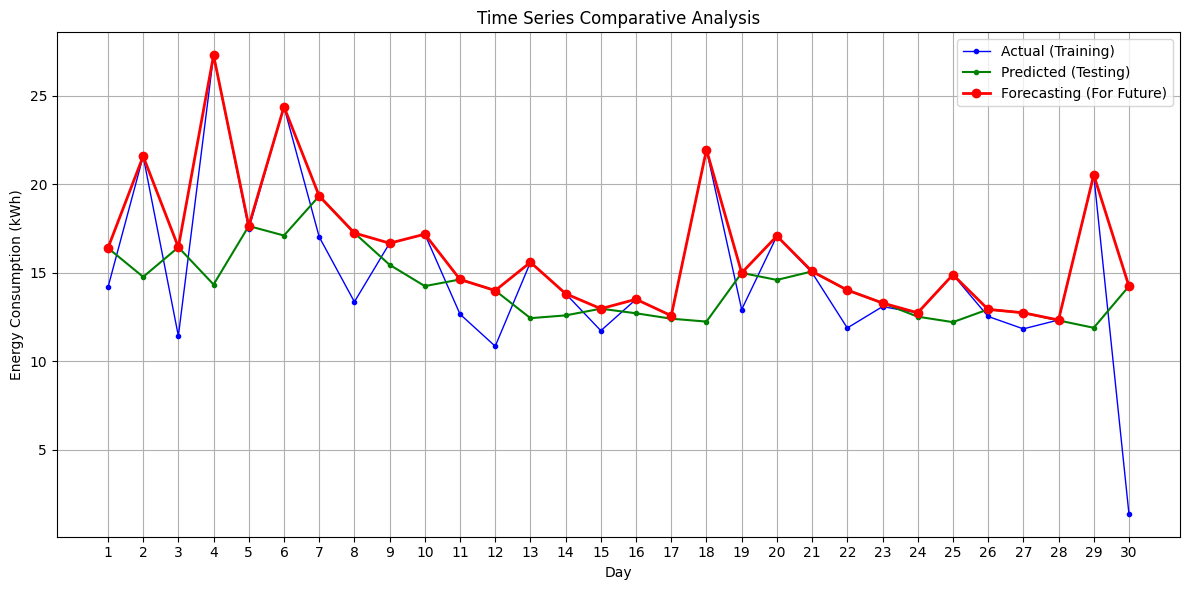

In [ ]:
assert 'Actual' in last_30_days.columns and 'Predicted' in last_30_days.columns, \
    "Columns 'Actual' and 'Predicted' must exist in last_30_days"

# Calculate the element-wise maximum between Actual and Predicted
forecasting_30_days = pd.DataFrame({
    'Forecasting': last_30_days[['Actual', 'Predicted']].max(axis=1)
})

# Generate x-axis labels (1 to N)
x_labels = range(1, len(last_30_days) + 1)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(x_labels, last_30_days['Actual'], marker='.', label='Actual (Training)', color='blue', linewidth=1)
plt.plot(x_labels, last_30_days['Predicted'], marker='.', label='Predicted (Testing)', color='green', linewidth=1.5)
plt.plot(x_labels, forecasting_30_days['Forecasting'], marker='o', label='Forecasting (For Future)', color='red', linewidth=2)

# Style
plt.xticks(x_labels)
plt.grid(True)
plt.xlabel('Day')
plt.ylabel('Energy Consumption (kWh)')
plt.legend()
plt.title('Time Series Comparative Analysis')
plt.tight_layout()
plt.show()

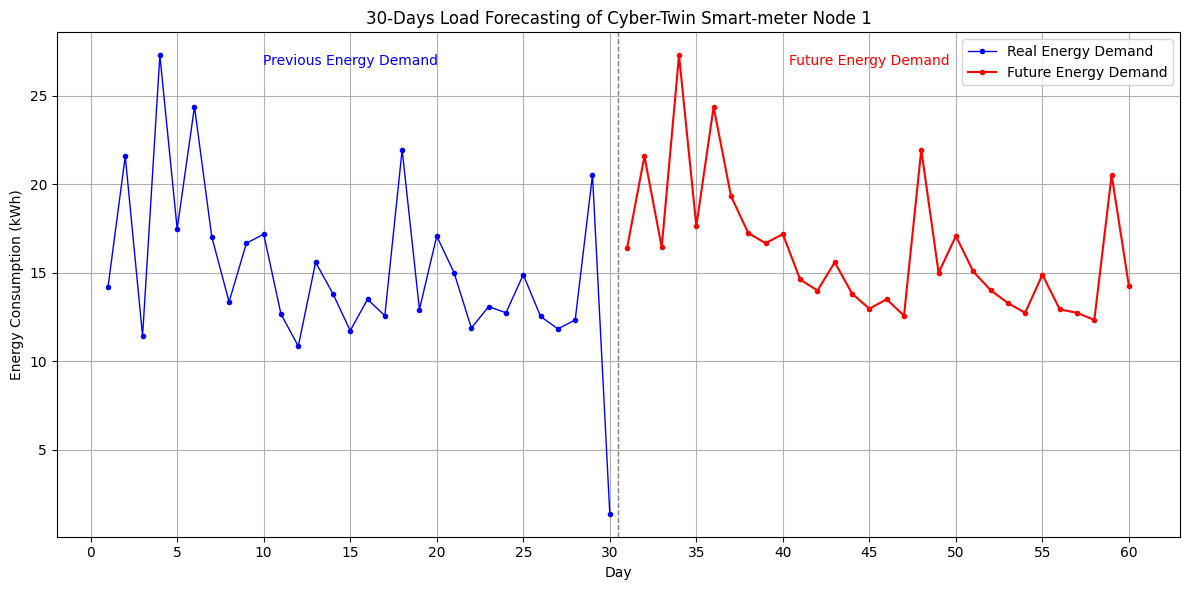

In [ ]:
# Create a new combined DataFrame
combined_df = pd.DataFrame({
    'Combined': pd.concat([last_30_days['Actual'], forecasting_30_days['Forecasting']], ignore_index=True)
})

# Create x-axis labels for 60 days
x_labels = range(1, len(combined_df) + 1)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(x_labels[:30], combined_df['Combined'][:30], marker='.', color='blue', label='Real Energy Demand', linewidth=1)
plt.plot(x_labels[30:], combined_df['Combined'][30:], marker='.', color='red', label='Future Energy Demand', linewidth=1.5)

# Add vertical separator between the two periods
plt.axvline(x=30.5, color='gray', linestyle='--', linewidth=1)
plt.text(15, combined_df['Combined'].max()*0.98, 'Previous Energy Demand', ha='center', color='blue', fontsize=10)
plt.text(45, combined_df['Combined'].max()*0.98, 'Future Energy Demand', ha='center', color='red', fontsize=10)

# Style
plt.grid(True)
plt.xticks(range(0, 61, 5))
plt.xlabel('Day')
plt.ylabel('Energy Consumption (kWh)')
plt.title('30-Days Load Forecasting of Cyber-Twin Smart-meter Node 1')
plt.legend()
plt.tight_layout()
plt.show()

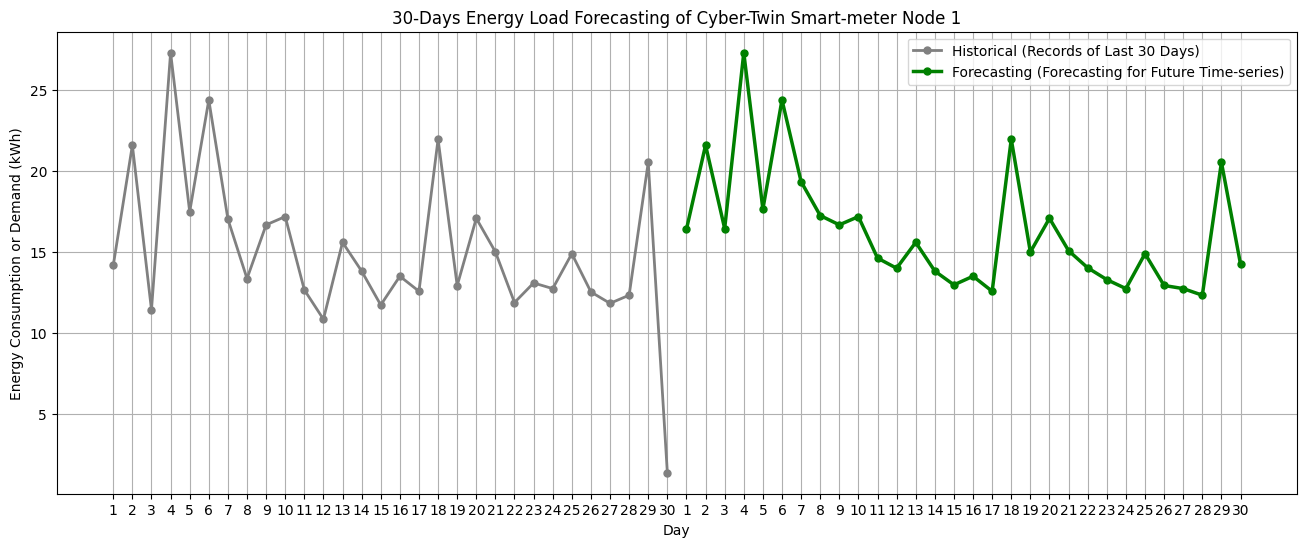

In [ ]:
# Generate a sequence of numbers for x-axis labels starting from 1
x_labels_last = range(1, len(last_30_days) + 1)

# Prepare data for next 30 days
x_labels_future = range(len(last_30_days) + 1, len(last_30_days) + 31)

# Plotting
plt.figure(figsize=(16, 6))
plt.plot(x_labels_last, last_30_days['Actual'], linewidth=2, marker='.', label='Historical (Records of Last 30 Days)', color='gray', markersize=10)
plt.plot(x_labels_future, forecasting_30_days['Forecasting'], linewidth=2.5, marker='.', label='Forecasting (Forecasting for Future Time-series)', color='green', markersize=10)


# Set x-ticks to include both ranges
plt.xticks(list(range(1, 31)) + list(range(31, 61)),
           list(range(1, 31)) + list(range(1, 31)))

# Set x-ticks to include both ranges
#plt.xticks(list(x_labels_last) + list(x_labels_future), list(range(1, len(last_30_days) + 1)) + list(range(len(last_30_days) + 1, len(last_30_days) + 31)))


# Set x-ticks to match the day labels
#plt.xticks(x_labels, fontsize=12)

# Add grid
plt.grid(True)

# Set labels and title
plt.xlabel('Day')
plt.ylabel('Energy Consumption or Demand (kWh)')
plt.legend()
plt.title('30-Days Energy Load Forecasting of Cyber-Twin Smart-meter Node 1')

# Show the plot
plt.show()

Train Loss (MSE): 0.011
Test Loss (MSE): 0.018
Mean Squared Error (MSE): 0.015
MSE based Accuracy: 99.985 %


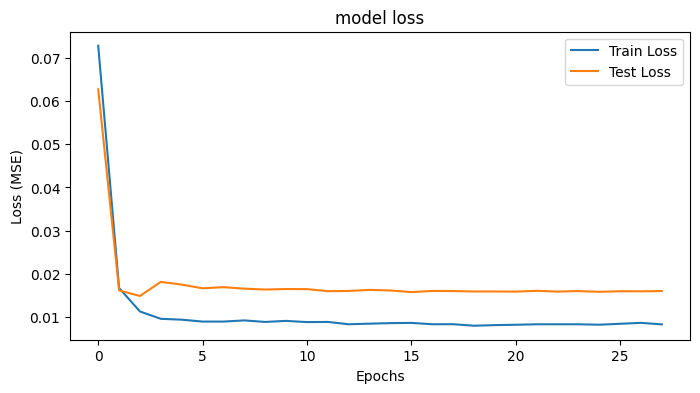

In [ ]:
# Mean Squared Error (MSE) Calculation

#MSE calculation for Regression Task

losses = history_sm1.history['loss']
val_losses = history_sm1.history['val_loss']

# Calculate the average loss across all epochs

average_loss = np.mean(losses)
print("Train Loss (MSE):", round(average_loss, 3)) #mse

# Calculate the average loss across all epochs
average_val_loss = np.mean(val_losses)
print("Test Loss (MSE):",round(average_val_loss, 3)) #mse

# Calculate overall MSE (simple average)
overall_mse = (average_loss + average_val_loss) / 2
print("Mean Squared Error (MSE):", round(overall_mse, 3))

accuracy = 100 - overall_mse
print("MSE based Accuracy:", round(accuracy, 3), "%")

plt.figure(figsize=(8,4))
plt.plot(history_sm1.history['loss'], label='Train Loss')
plt.plot(history_sm1.history['val_loss'], label='Test Loss')
plt.title('model loss')
plt.ylabel('Loss (MSE)')
plt.xlabel('Epochs')
plt.legend(loc='upper right')
plt.show();

Root Mean Squared Error (RMSE): 0.121
RMSE based Accuracy: 99.879 %


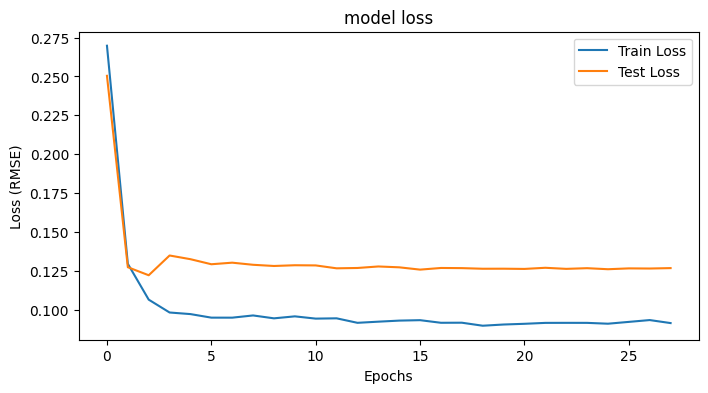

In [ ]:
# Calculate RMSE
rmse_value = np.sqrt(overall_mse)

print("Root Mean Squared Error (RMSE):", round(rmse_value, 3))
accuracy = 100 - rmse_value
print("RMSE based Accuracy:", round(accuracy, 3), "%")

sqrt_rmse_losses = np.sqrt(history_sm1.history['loss'])
sqrt_rmse_val_losses = np.sqrt(history_sm1.history['val_loss'])

plt.figure(figsize=(8,4))
plt.plot(sqrt_rmse_losses, label='Train Loss')
plt.plot(sqrt_rmse_val_losses, label='Test Loss')
plt.title('model loss')
plt.ylabel('Loss (RMSE)')
plt.xlabel('Epochs')
plt.legend(loc='upper right')
plt.show();

Training MAE:  0.072
Validation or Test MAE:  0.092
Overall MAE (Simple Average): 0.082
MAE based Accuracy: 99.91809388749036 %


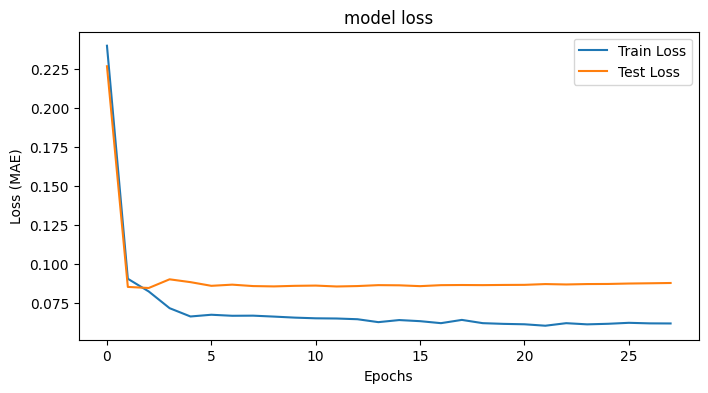

In [ ]:
# Mean Absolute Error (MSE) Calculation
mae_train = history_sm1.history['mae']          # MAE for training set
mae_test = history_sm1.history['val_mae']
average_mae_train = np.mean(mae_train)
average_mae_test = np.mean(mae_test)
print("Training MAE: ", round(average_mae_train, 3))
print(f"Validation or Test MAE: ",  round(average_mae_test, 3))

overall_mae = (average_mae_train + average_mae_test) / 2
print(f"Overall MAE (Simple Average): {overall_mae:.3f}")

accuracy = 100 - overall_mae
print("MAE based Accuracy:", accuracy, "%")

plt.figure(figsize=(8,4))
plt.plot(history_sm1.history['mae'], label='Train Loss')
plt.plot(history_sm1.history['val_mae'], label='Test Loss')
plt.title('model loss')
plt.ylabel('Loss (MAE)')
plt.xlabel('Epochs')
plt.legend(loc='upper right')
plt.show();

In [ ]:
Overall_accuracy_score = (overall_mae+rmse_value+overall_mse)/3
print("accuracy score for cyber-twin node 1:", Overall_accuracy_score)
accuracy_per = 100 - Overall_accuracy_score
print("Accuracy:", round(accuracy_per, 3), "%")

accuracy score for cyber-twin node 1: 0.07248108371703522
Accuracy: 99.928 %


# **Cyber-Twin Node 2: Local Training, Encryption, and Load Forecasting Plot**

In [ ]:
# Decrypt data for computation
df2_decrypted = decrypt_dataframe(cyber_twins["meter2"], AES_key, HMAC_key)
df2_decrypted.head(5)

,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min
0,MAC000246,12/3/2011,0.115,0.300233333,1.179,30,0.361230911,9.007,0.047
1,MAC000246,12/4/2011,0.175,0.432562504,1.914,48,0.484151596,20.7630002,0.026
2,MAC000246,12/5/2011,0.078,0.125416667,0.934,48,0.153326773,6.02,0.025
3,MAC000246,12/6/2011,0.114,0.277541669,1.216,48,0.313398668,13.3220001,0.027
4,MAC000246,12/7/2011,0.1035,0.188791667,0.873,48,0.209613013,9.062,0.026


In [ ]:
scaler2 = scaler_global
look_back2 = look_back_global
X_train2, y_train2, X_test2, y_test2, dates2 = prepare_data(df2_decrypted, scaler2, look_back2)

          date  Energy_kWh
0   2011-12-03       9.007
1   2011-12-04      20.763
2   2011-12-05       6.020
3   2011-12-06      13.322
4   2011-12-07       9.062
..         ...         ...
814 2014-02-24      18.935
815 2014-02-25      23.717
816 2014-02-26      15.562
817 2014-02-27      16.026
818 2014-02-28       0.145

[819 rows x 2 columns]


In [ ]:
enc_X_test2  = encrypt_train_test_components(AES_key, HMAC_key, X_test2)
enc_y_test2  = encrypt_train_test_components(AES_key, HMAC_key, y_test2)
enc_look_back2 = encrypt_train_test_components(AES_key, HMAC_key, look_back2)
enc_scaler2 = encrypt_train_test_components(AES_key, HMAC_key, scaler2)

In [ ]:
model2 = create_lstm_model(look_back2)

/tmp/ipython-input-745509497.py:17: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(RelativeDirectional, self).__init__(**kwargs)


In [ ]:
weights_sm2, history_sm2 = local_train(
    model2,
    X_train2, y_train2,
    X_test2, y_test2
)

Epoch 1/50
25/25 - 7s - 266ms/step - accuracy: 0.0013 - loss: 0.0343 - mae: 0.1434 - val_accuracy: 0.0000e+00 - val_loss: 0.0322 - val_mae: 0.1470
Epoch 2/50
25/25 - 0s - 8ms/step - accuracy: 0.0013 - loss: 0.0229 - mae: 0.1220 - val_accuracy: 0.0000e+00 - val_loss: 0.0298 - val_mae: 0.1368
Epoch 3/50
25/25 - 0s - 11ms/step - accuracy: 0.0013 - loss: 0.0204 - mae: 0.1126 - val_accuracy: 0.0000e+00 - val_loss: 0.0305 - val_mae: 0.1411
Epoch 4/50
25/25 - 0s - 7ms/step - accuracy: 0.0013 - loss: 0.0204 - mae: 0.1132 - val_accuracy: 0.0000e+00 - val_loss: 0.0306 - val_mae: 0.1409
Epoch 5/50
25/25 - 0s - 8ms/step - accuracy: 0.0013 - loss: 0.0204 - mae: 0.1135 - val_accuracy: 0.0000e+00 - val_loss: 0.0308 - val_mae: 0.1415
Epoch 6/50
25/25 - 0s - 8ms/step - accuracy: 0.0013 - loss: 0.0204 - mae: 0.1133 - val_accuracy: 0.0000e+00 - val_loss: 0.0312 - val_mae: 0.1430
Epoch 7/50
25/25 - 0s - 7ms/step - accuracy: 0.0013 - loss: 0.0202 - mae: 0.1129 - val_accuracy: 0.0000e+00 - val_loss: 0.0311 

**Encrypting weights for Federated Learning Aggregation Process**

In [ ]:
# Encrypt model weights
enc_weights2 = encrypt_model_weights(weights_sm2, AES_key, HMAC_key)
print("Model weights encrypted at cyber-twin node 2.")
print(enc_weights2)

Model weights encrypted at cyber-twin node 2.
[b'...']


**Load Forecasting for individual Smart-meter user**

In [ ]:
pred2 = forecast(model2, X_test2, scaler2)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 457ms/step


In [ ]:
# Create a DataFrame for actual and predicted values
predicted_df2 = pd.DataFrame(data={'Actual': scaler2.inverse_transform(y_test2.reshape(-1, 1)).flatten(),
                                   'Predicted': pred2.flatten()},
                            index=df2_decrypted.index[-len(y_test2):])

# Select the last 30 days
last_30_days = predicted_df2.tail(30)

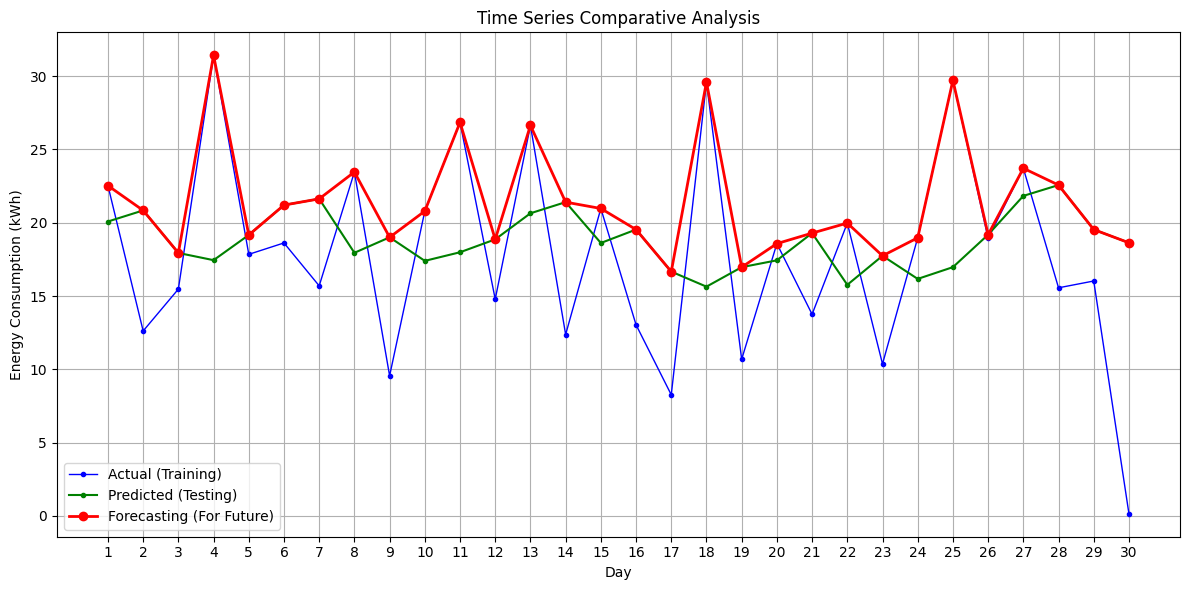

In [ ]:
assert 'Actual' in last_30_days.columns and 'Predicted' in last_30_days.columns, \
    "Columns 'Actual' and 'Predicted' must exist in last_30_days"

# Calculate the element-wise maximum between Actual and Predicted
forecasting_30_days = pd.DataFrame({
    'Forecasting': last_30_days[['Actual', 'Predicted']].max(axis=1)
})

# Generate x-axis labels (1 to N)
x_labels = range(1, len(last_30_days) + 1)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(x_labels, last_30_days['Actual'], marker='.', label='Actual (Training)', color='blue', linewidth=1)
plt.plot(x_labels, last_30_days['Predicted'], marker='.', label='Predicted (Testing)', color='green', linewidth=1.5)
plt.plot(x_labels, forecasting_30_days['Forecasting'], marker='o', label='Forecasting (For Future)', color='red', linewidth=2)

# Style
plt.xticks(x_labels)
plt.grid(True)
plt.xlabel('Day')
plt.ylabel('Energy Consumption (kWh)')
plt.legend()
plt.title('Time Series Comparative Analysis')
plt.tight_layout()
plt.show()

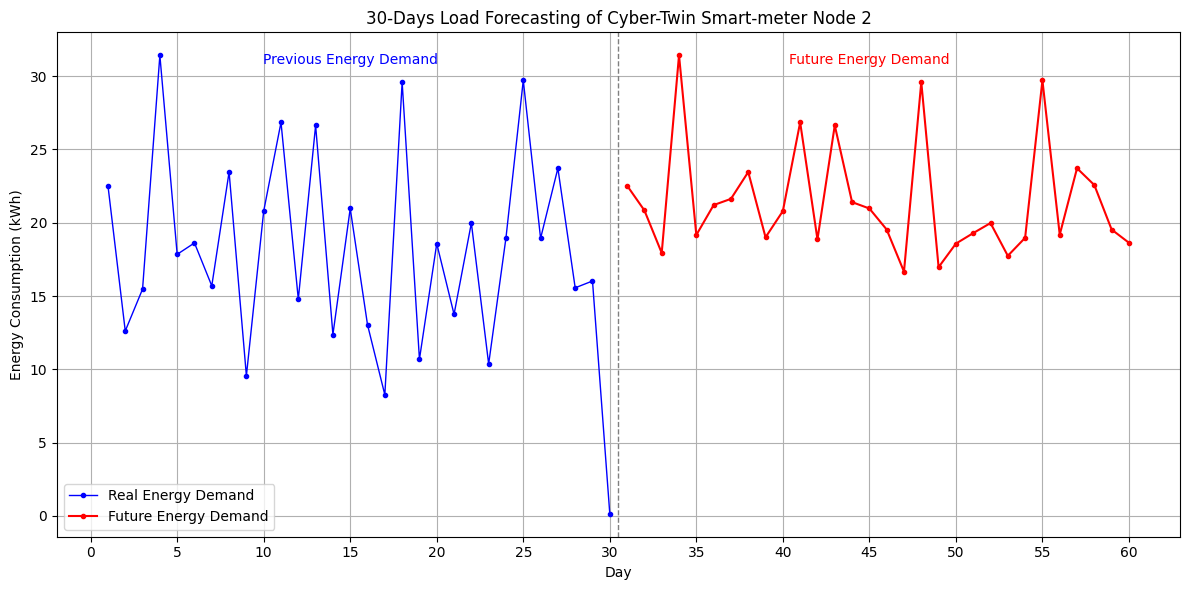

In [ ]:
# Create a new combined DataFrame
combined_df = pd.DataFrame({
    'Combined': pd.concat([last_30_days['Actual'], forecasting_30_days['Forecasting']], ignore_index=True)
})

# Create x-axis labels for 60 days
x_labels = range(1, len(combined_df) + 1)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(x_labels[:30], combined_df['Combined'][:30], marker='.', color='blue', label='Real Energy Demand', linewidth=1)
plt.plot(x_labels[30:], combined_df['Combined'][30:], marker='.', color='red', label='Future Energy Demand', linewidth=1.5)

# Add vertical separator between the two periods
plt.axvline(x=30.5, color='gray', linestyle='--', linewidth=1)
plt.text(15, combined_df['Combined'].max()*0.98, 'Previous Energy Demand', ha='center', color='blue', fontsize=10)
plt.text(45, combined_df['Combined'].max()*0.98, 'Future Energy Demand', ha='center', color='red', fontsize=10)

# Style
plt.grid(True)
plt.xticks(range(0, 61, 5))
plt.xlabel('Day')
plt.ylabel('Energy Consumption (kWh)')
plt.title('30-Days Load Forecasting of Cyber-Twin Smart-meter Node 2')
plt.legend()
plt.tight_layout()
plt.show()

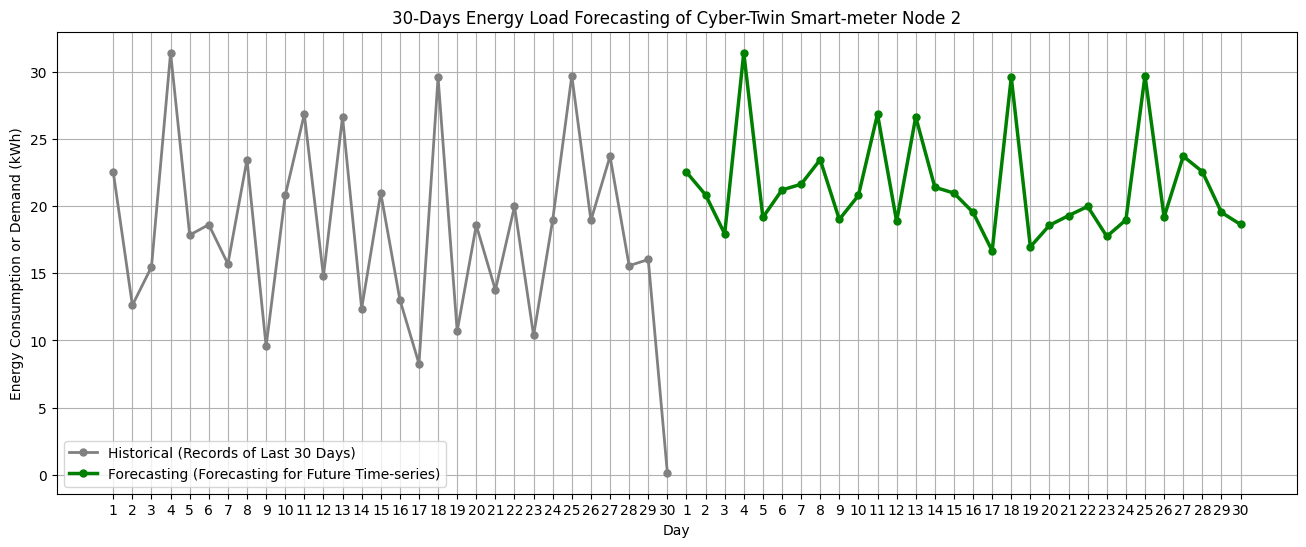

In [ ]:
# Generate a sequence of numbers for x-axis labels starting from 1
x_labels_last = range(1, len(last_30_days) + 1)

# Prepare data for next 30 days
x_labels_future = range(len(last_30_days) + 1, len(last_30_days) + 31)

# Plotting
plt.figure(figsize=(16, 6))
plt.plot(x_labels_last, last_30_days['Actual'], linewidth=2, marker='.', label='Historical (Records of Last 30 Days)', color='gray', markersize=10)
plt.plot(x_labels_future, forecasting_30_days['Forecasting'], linewidth=2.5, marker='.', label='Forecasting (Forecasting for Future Time-series)', color='green', markersize=10)


# Set x-ticks to include both ranges
plt.xticks(list(range(1, 31)) + list(range(31, 61)),
           list(range(1, 31)) + list(range(1, 31)))

# Set x-ticks to include both ranges
#plt.xticks(list(x_labels_last) + list(x_labels_future), list(range(1, len(last_30_days) + 1)) + list(range(len(last_30_days) + 1, len(last_30_days) + 31)))


# Set x-ticks to match the day labels
#plt.xticks(x_labels, fontsize=12)

# Add grid
plt.grid(True)

# Set labels and title
plt.xlabel('Day')
plt.ylabel('Energy Consumption or Demand (kWh)')
plt.legend()
plt.title('30-Days Energy Load Forecasting of Cyber-Twin Smart-meter Node 2')

# Show the plot
plt.show()

Train Loss (MSE): 0.021
Test Loss (MSE): 0.031
Mean Squared Error (MSE): 0.026
MSE based Accuracy: 99.974 %


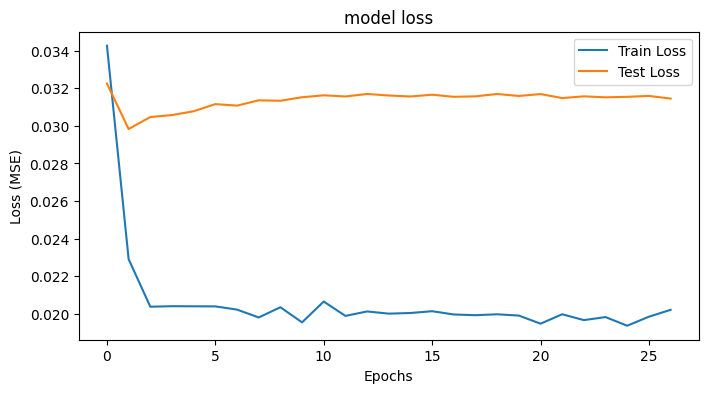

In [ ]:
# Mean Squared Error (MSE) Calculation

#MSE calculation for Regression Task

losses = history_sm2.history['loss']
val_losses = history_sm2.history['val_loss']

# Calculate the average loss across all epochs

average_loss = np.mean(losses)
print("Train Loss (MSE):", round(average_loss, 3)) #mse

# Calculate the average loss across all epochs
average_val_loss = np.mean(val_losses)
print("Test Loss (MSE):",round(average_val_loss, 3)) #mse

# Calculate overall MSE (simple average)
overall_mse = (average_loss + average_val_loss) / 2
print("Mean Squared Error (MSE):", round(overall_mse, 3))

accuracy = 100 - overall_mse
print("MSE based Accuracy:", round(accuracy, 3), "%")

plt.figure(figsize=(8,4))
plt.plot(history_sm2.history['loss'], label='Train Loss')
plt.plot(history_sm2.history['val_loss'], label='Test Loss')
plt.title('model loss')
plt.ylabel('Loss (MSE)')
plt.xlabel('Epochs')
plt.legend(loc='upper right')
plt.show();

Root Mean Squared Error (RMSE): 0.161
RMSE based Accuracy: 99.839 %


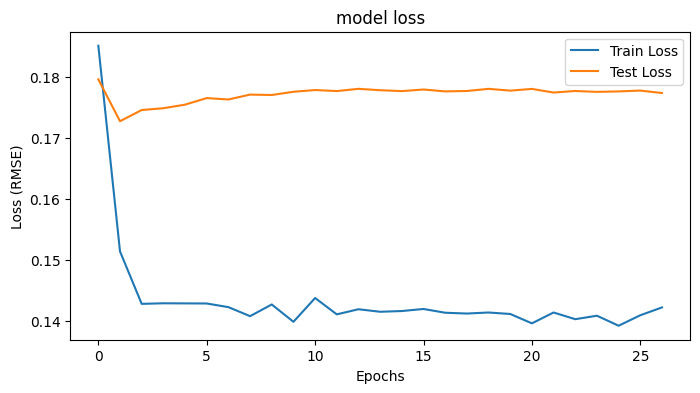

In [ ]:
# Calculate RMSE
rmse_value = np.sqrt(overall_mse)

print("Root Mean Squared Error (RMSE):", round(rmse_value, 3))
accuracy = 100 - rmse_value
print("RMSE based Accuracy:", round(accuracy, 3), "%")

sqrt_rmse_losses = np.sqrt(history_sm2.history['loss'])
sqrt_rmse_val_losses = np.sqrt(history_sm2.history['val_loss'])

plt.figure(figsize=(8,4))
plt.plot(sqrt_rmse_losses, label='Train Loss')
plt.plot(sqrt_rmse_val_losses, label='Test Loss')
plt.title('model loss')
plt.ylabel('Loss (RMSE)')
plt.xlabel('Epochs')
plt.legend(loc='upper right')
plt.show();

Training MAE:  0.114
Validation or Test MAE:  0.143
Overall MAE (Simple Average): 0.128
MAE based Accuracy: 99.87162295011458 %


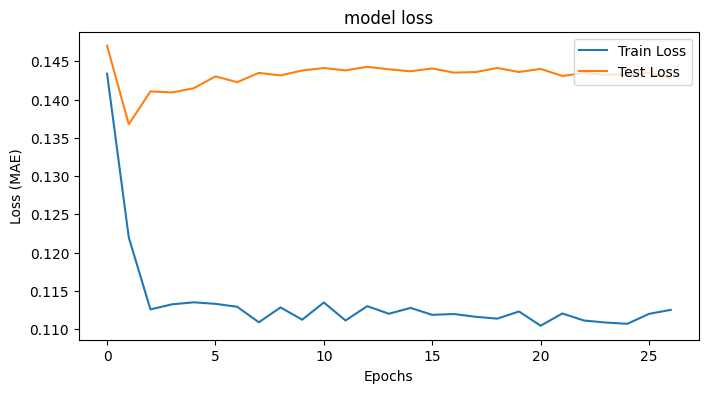

In [ ]:
# Mean Absolute Error (MSE) Calculation
mae_train = history_sm2.history['mae']          # MAE for training set
mae_test = history_sm2.history['val_mae']
average_mae_train = np.mean(mae_train)
average_mae_test = np.mean(mae_test)
print("Training MAE: ", round(average_mae_train, 3))
print(f"Validation or Test MAE: ",  round(average_mae_test, 3))

overall_mae = (average_mae_train + average_mae_test) / 2
print(f"Overall MAE (Simple Average): {overall_mae:.3f}")

accuracy = 100 - overall_mae
print("MAE based Accuracy:", accuracy, "%")

plt.figure(figsize=(8,4))
plt.plot(history_sm2.history['mae'], label='Train Loss')
plt.plot(history_sm2.history['val_mae'], label='Test Loss')
plt.title('model loss')
plt.ylabel('Loss (MAE)')
plt.xlabel('Epochs')
plt.legend(loc='upper right')
plt.show();

In [ ]:
Overall_accuracy_score = (overall_mae+rmse_value+overall_mse)/3
print("accuracy score for cyber-twin node 2:", Overall_accuracy_score)
accuracy_per = 100 - Overall_accuracy_score
print("Accuracy:", round(accuracy_per, 3), "%")

accuracy score for cyber-twin node 2: 0.10523536585634623
Accuracy: 99.895 %


# **Criptographic Federated Learning Aggregation at AMI server Node**

**Federated Learning Aggregation via Summation Weight Scaling (FedAggSum_WeightScaling)**


In [ ]:
X_test1_dec  = decrypt_train_test_components(AES_key, HMAC_key, enc_X_test1)
y_test1_dec  = decrypt_train_test_components(AES_key, HMAC_key, enc_y_test1)

X_test2_dec  = decrypt_train_test_components(AES_key, HMAC_key, enc_X_test2)
y_test2_dec  = decrypt_train_test_components(AES_key, HMAC_key, enc_y_test2)

In [ ]:
# Sum test data
X_test_sum = X_test1_dec + X_test2_dec
y_test_sum = y_test1_dec + y_test2_dec

In [ ]:
global_model = create_lstm_model(look_back_global)

/tmp/ipython-input-745509497.py:17: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(RelativeDirectional, self).__init__(**kwargs)


In [ ]:
dec_weights1 = decrypt_model_weights(enc_weights1, global_model, AES_key, HMAC_key)
dec_weights2 = decrypt_model_weights(enc_weights2, global_model, AES_key, HMAC_key)

print("Encrypted model updates decrypted at AMI server")

Encrypted model updates decrypted at AMI server


**Weight Scaling based Federated Learning Aggregation via Summation**

In [ ]:
def federated_learning_summation_with_scaling(weights_list, scale):
    aggregated_weights = []
    for layer_weights in zip(*weights_list):
        layer_sum = np.sum(layer_weights, axis=0)
        aggregated_weights.append(layer_sum * scale)
    return aggregated_weights

aggregated_weights = federated_learning_summation_with_scaling(
    [weights_sm1, weights_sm2],
    scale=0.90   # Reduce 10% of aggregated_weights for good prediction
)

In [ ]:
# Single Node Weight based Federated Learning Aggregation
global_model.set_weights(aggregated_weights)
print("Global model updated with weights")

Global model updated with weights


In [ ]:
pred_global = forecast(global_model, X_test_sum, scaler_global)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step


In [ ]:
# Create a DataFrame for actual and predicted values
predicted_df_global = pd.DataFrame(data={'Actual': scaler1.inverse_transform(y_test_sum.reshape(-1, 1)).flatten(),
                                   'Predicted': pred_global.flatten()}, index=range(len(y_test_sum))) # simple 0,1,2,... index

# Select the last 30 days
last_30_days = predicted_df_global.tail(30)

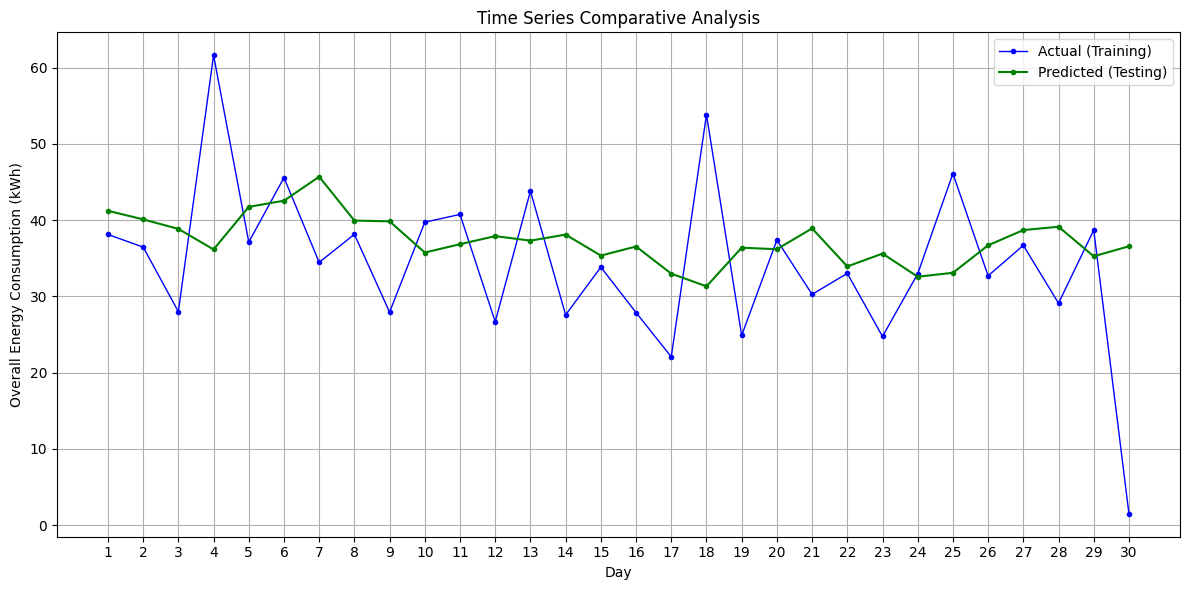

In [ ]:
assert 'Actual' in last_30_days.columns and 'Predicted' in last_30_days.columns, \
    "Columns 'Actual' and 'Predicted' must exist in last_30_days"

# Generate x-axis labels (1 to N)
x_labels = range(1, len(last_30_days) + 1)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(x_labels, last_30_days['Actual'], marker='.', label='Actual (Training)', color='blue', linewidth=1)
plt.plot(x_labels, last_30_days['Predicted'], marker='.', label='Predicted (Testing)', color='green', linewidth=1.5)

# Style
plt.xticks(x_labels)
plt.grid(True)
plt.xlabel('Day')
plt.ylabel('Overall Energy Consumption (kWh)')
plt.legend()
plt.title('Time Series Comparative Analysis')
plt.tight_layout()
plt.show()

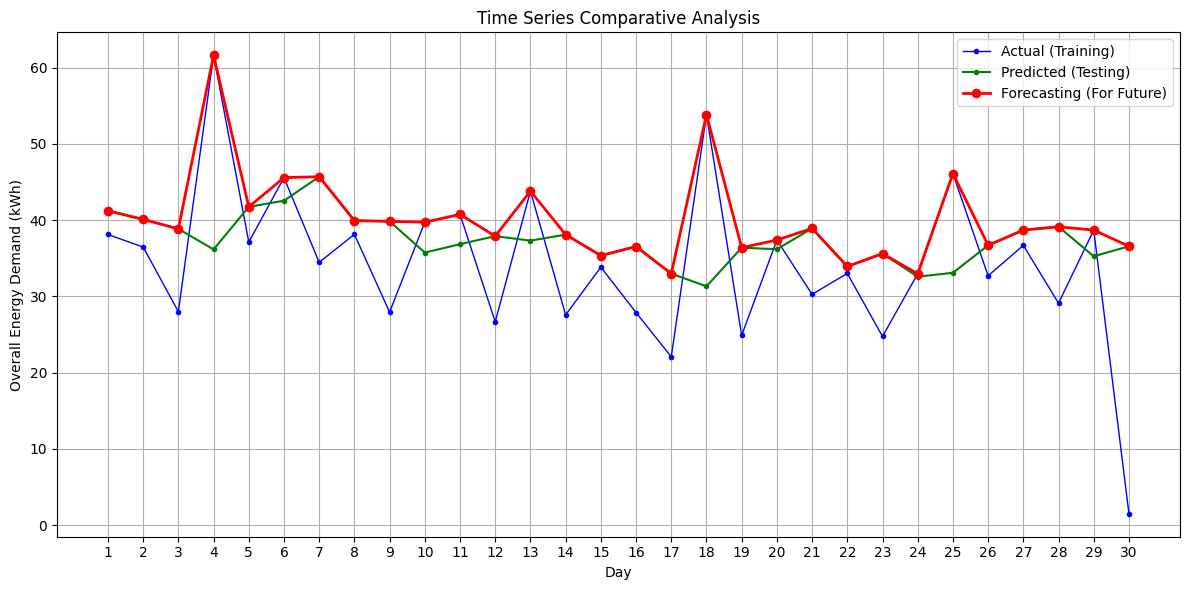

In [ ]:

# Calculate the element-wise maximum between Actual and Predicted for forecasting risk free energy demand
forecasting_30_days = pd.DataFrame({
    'Forecasting': last_30_days[['Actual', 'Predicted']].max(axis=1)
})

# Generate x-axis labels (1 to N)
x_labels = range(1, len(last_30_days) + 1)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(x_labels, last_30_days['Actual'], marker='.', label='Actual (Training)', color='blue', linewidth=1)
plt.plot(x_labels, last_30_days['Predicted'], marker='.', label='Predicted (Testing)', color='green', linewidth=1.5)
plt.plot(x_labels, forecasting_30_days['Forecasting'], marker='o', label='Forecasting (For Future)', color='red', linewidth=2)

# Style
plt.xticks(x_labels)
plt.grid(True)
plt.xlabel('Day')
plt.ylabel('Overall Energy Demand (kWh)')
plt.legend()
plt.title('Time Series Comparative Analysis')
plt.tight_layout()
plt.show()


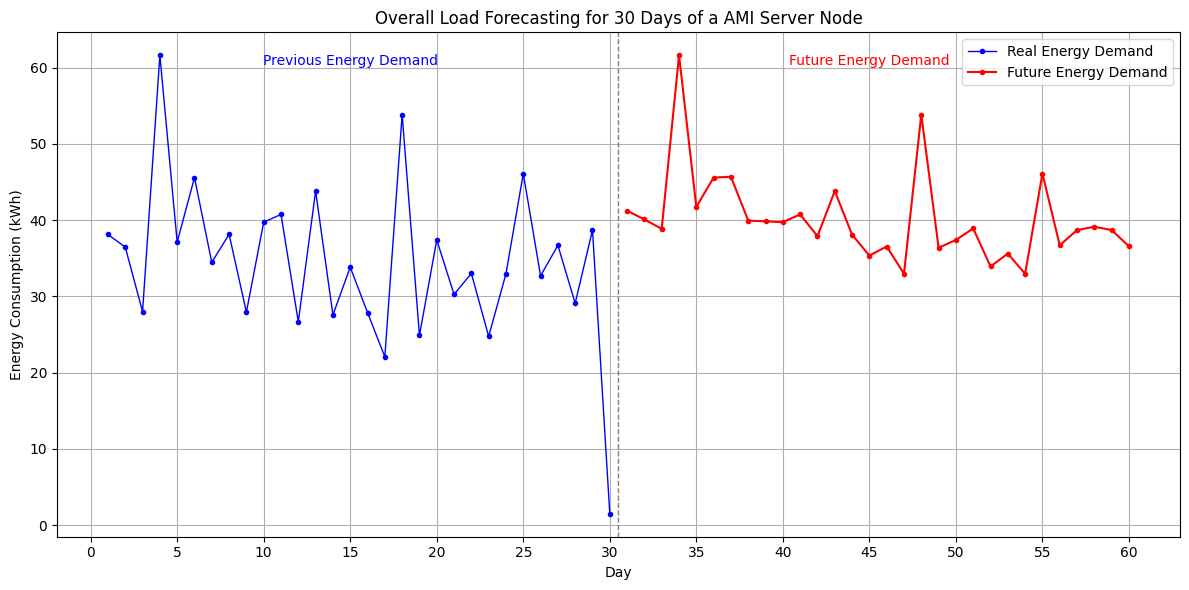

In [ ]:
# Create a new combined DataFrame
combined_df = pd.DataFrame({
    'Combined': pd.concat([last_30_days['Actual'], forecasting_30_days['Forecasting']], ignore_index=True)
})

# Create x-axis labels for 60 days
x_labels = range(1, len(combined_df) + 1)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(x_labels[:30], combined_df['Combined'][:30], marker='.', color='blue', label='Real Energy Demand', linewidth=1)
plt.plot(x_labels[30:], combined_df['Combined'][30:], marker='.', color='red', label='Future Energy Demand', linewidth=1.5)

# Add vertical separator between the two periods
plt.axvline(x=30.5, color='gray', linestyle='--', linewidth=1)
plt.text(15, combined_df['Combined'].max()*0.98, 'Previous Energy Demand', ha='center', color='blue', fontsize=10)
plt.text(45, combined_df['Combined'].max()*0.98, 'Future Energy Demand', ha='center', color='red', fontsize=10)

# Style
plt.grid(True)
plt.xticks(range(0, 61, 5))
plt.xlabel('Day')
plt.ylabel('Energy Consumption (kWh)')
plt.title('Overall Load Forecasting for 30 Days of a AMI Server Node')
plt.legend()
plt.tight_layout()
plt.show()

# **LLM Integration for realistic forecasting for SCADA-based sbstation-grid**



In [ ]:
!pip install torch transformers sentence-transformers

In [ ]:
from sentence_transformers import SentenceTransformer # small sentence-transformer model for season embeddings:
import torch

# Load lightweight BERT-based embedding model
bert_model = SentenceTransformer('all-MiniLM-L6-v2')  # CPU-friendly

# Define seasons
seasons = ["Winter", "Summer", "Spring", "Autumn"]

# Get embeddings
season_embeddings = bert_model.encode(seasons)  # shape: (4, 384)

In [ ]:
values = forecasting_30_days['Forecasting'].tolist()

area = "London"
season = "Winter"
notes = "Energy demand increases due to heating usage"

In [ ]:
prompt = f"""
Adjust the following forecast values using the context.

Values: {values}
Area: {area}
Season: {season}
Notes: {notes}

Return ONLY a Python list of adjusted numbers.
"""

In [ ]:
inputs = tokenizer(prompt, return_tensors="pt")

output = model.generate(
    **inputs,
    max_new_tokens=100,   # ⬅ increase a bit
    do_sample=False
)

result = tokenizer.decode(output[0], skip_special_tokens=True)
print(result)

In [ ]:
import re

adjusted_forecast = list(map(
    float,
    re.findall(r"-?\d+\.\d+", result)
))

In [ ]:
original_forecast = forecasting_30_days['Forecasting'].values

n = min(len(original_forecast), len(adjusted_forecast))
adjusted_forecast = adjusted_forecast[:n]
original_forecast = original_forecast[:n]

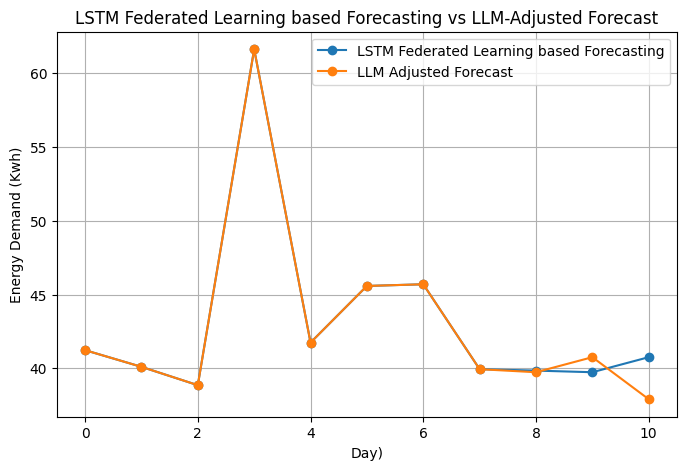

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(original_forecast, label="LSTM Federated Learning based Forecasting", marker="o")
plt.plot(adjusted_forecast, label="LLM Adjusted Forecast", marker="o")

plt.title("LSTM Federated Learning based Forecasting vs LLM-Adjusted Forecast")
plt.xlabel("Day)")
plt.ylabel("Energy Demand (Kwh)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Convert to numpy arrays for easier math
original_forecast = forecasting_30_days['Forecasting'].values
adjusted_forecast = np.array(adjusted_forecast)  # LLM output for first 11 points

# Calculate absolute difference for first 11 points
difference_factor = np.abs(adjusted_forecast[:11] - original_forecast[:11])

In [ ]:
mean_difference = np.mean(difference_factor)
print(f"Mean absolute difference for first 11 points: {mean_difference:.4f}")

Mean absolute difference for first 11 points: 0.3617


In [ ]:
# Prepare full adjusted forecast array with length 30
full_adjusted_forecast = np.zeros_like(original_forecast)

# Fill first 11 points with your LLM adjusted forecast
full_adjusted_forecast[:11] = adjusted_forecast[:11]

# For points 11 to 29, add mean difference to original forecast
full_adjusted_forecast[11:] = original_forecast[11:] + mean_difference

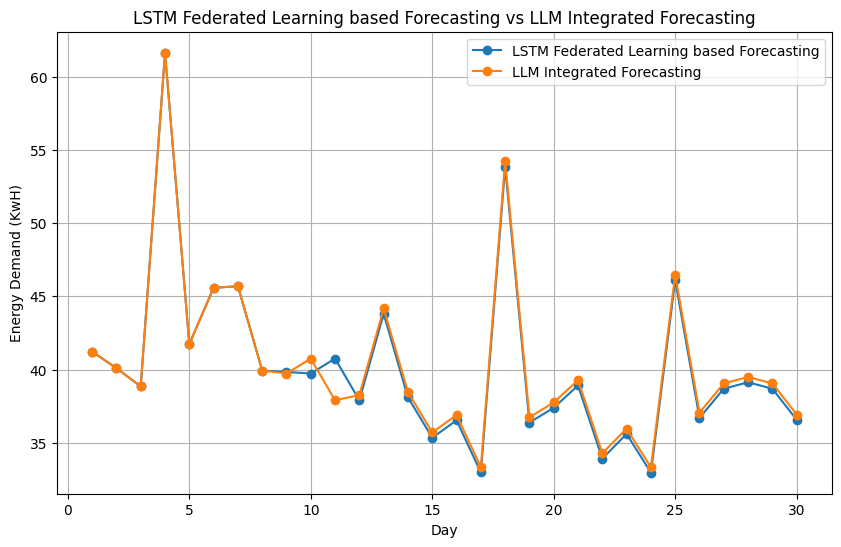

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(np.arange(1, len(original_forecast) + 1), original_forecast, label="LSTM Federated Learning based Forecasting", marker="o")
plt.plot(np.arange(1, len(full_adjusted_forecast) + 1), full_adjusted_forecast, label="LLM Integrated Forecasting", marker="o")

plt.title("LSTM Federated Learning based Forecasting vs LLM Integrated Forecasting")
plt.xlabel("Day")
plt.ylabel("Energy Demand (KwH)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
end_time = time.time()

print(f"Execution time: {end_time - start_time:.4f} seconds")

Execution time: 128.7842 seconds
